In [40]:
### setup
import numpy as np
import random
import os
from pathlib import Path

!pip install xgboost lightgbm
!pip install econml -q

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)

# Ścieżka do podmiany
ROOT_DIR    = Path("C:/Users/User/Desktop/Empik workspace")
DATA_FILE   = ROOT_DIR / "bank_data_prediction.csv"
OUTPUT_DIR  = ROOT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_COL    = "y"
LEAKAGE_COLS  = ["duration"]

In [41]:
### 1. Wczytanie danych
import pandas as pd

df = pd.read_csv(DATA_FILE, sep=",", index_col=0)
print("Kolumny:", df.columns.tolist())
print("Shape:", df.shape)
print("\ntest_control_flag unikalne:", df["test_control_flag"].value_counts())

# Przegląd danych
print("=== SHAPE ===")
print(df.shape)

print("\n=== TYPY KOLUMN ===")
print(df.dtypes)

print("\n=== PIERWSZE WIERSZE ===")
print(df.head(3).to_string())

print("\n=== BRAKI DANYCH ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.concat([missing, missing_pct], axis=1, keys=["n_missing", "%"]).query("n_missing > 0"))

print("\n=== DUPLIKATY ===")
print(f"Liczba duplikatów: {df.duplicated().sum()}")

print("\n=== DESCRIBE (numeryczne) ===")
print(df.describe().T.to_string())

print("\n=== DESCRIBE (kategoryczne) ===")
print(df.describe(include="object").T.to_string())

print("\n=== UNIKALNE WARTOŚCI per kolumna ===")
for col in df.columns:
    n = df[col].nunique()
    sample = df[col].unique()[:5]
    print(f"  {col:25s} unique={n:5d}  sample={sample}")

C:\Users\User\AppData\Local\Temp\ipykernel_19744\3102629335.py:4: DtypeWarning: Columns (8,9,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_FILE, sep=",", index_col=0)


Kolumny: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'test_control_flag']
Shape: (41188, 22)

test_control_flag unikalne: test_control_flag
control group     24712
campaign group    16476
Name: count, dtype: int64
=== SHAPE ===
(41188, 22)

=== TYPY KOLUMN ===
age                    int64
job                   object
marital               object
education             object
default               object
housing               object
loan                  object
contact               object
month                 object
day_of_week           object
duration             float64
campaign             float64
pdays                  int64
previous               int64
poutcome              object
emp.var.rate         float64
cons.price.idx       float64
cons.conf.idx        float64
euribor3m       

In [42]:
### 2. Definicja Treatment i Balance Check
from scipy import stats

print("Rozkład test_control_flag:\n", df["test_control_flag"].value_counts())

df["W"] = (df["test_control_flag"] == "campaign group").astype(int)

control   = df[df["W"] == 0]
treatment = df[df["W"] == 1]

print(f"\nBalance W: control={( df.W==0).sum()}  treatment={(df.W==1).sum()}")

numeric_cols     = df.select_dtypes(include="number").columns.difference(["W", TARGET_COL])
categorical_cols = df.select_dtypes(include="object").columns.difference([TARGET_COL, "test_control_flag"])

balance_results = []

for col in numeric_cols:
    stat, p = stats.ttest_ind(
        control[col].dropna(),
        treatment[col].dropna(),
        equal_var=False
    )
    mean_c = control[col].mean()
    mean_t = treatment[col].mean()
    std_pool = df[col].std()
    smd = (mean_t - mean_c) / std_pool if std_pool > 0 else 0
    balance_results.append({
        "feature": col, "type": "numeric",
        "mean_control": round(mean_c, 4), "mean_treatment": round(mean_t, 4),
        "SMD": round(smd, 4), "p_value": round(p, 4),
        "balanced": "✅ OK" if (abs(smd) < 0.1 and p > 0.05) else "⚠ NIEZBALANSOWANE"
    })

for col in categorical_cols:
    ct = pd.crosstab(df[col], df["W"])
    if ct.shape[1] == 2:
        chi2, p, _, _ = stats.chi2_contingency(ct)
        balance_results.append({
            "feature": col, "type": "categorical",
            "mean_control": "-", "mean_treatment": "-",
            "SMD": "-", "p_value": round(p, 4),
            "balanced": "✅ OK" if p > 0.05 else "⚠ NIEZBALANSOWANE"
        })

balance_df = pd.DataFrame(balance_results)
print("\n=== BALANCE CHECK ===")
print(balance_df.to_string(index=False))

unbalanced = balance_df[balance_df["balanced"].str.startswith("⚠")]
print(f"\nCechy niezbalansowane: {len(unbalanced)}/{len(balance_df)}")
if len(unbalanced) > 0:
    print("⚠ Uwaga: niezbalansowane cechy mogą zaburzać uplift — rozważ IPW lub matching")
    print(unbalanced[["feature", "p_value", "SMD"]].to_string(index=False))

Rozkład test_control_flag:
 test_control_flag
control group     24712
campaign group    16476
Name: count, dtype: int64

Balance W: control=24712  treatment=16476

=== BALANCE CHECK ===
       feature        type mean_control mean_treatment     SMD  p_value          balanced
           age     numeric      40.0482        39.9879 -0.0058   0.5664              ✅ OK
      campaign     numeric          NaN         2.5469     NaN      NaN ⚠ NIEZBALANSOWANE
 cons.conf.idx     numeric     -40.4839       -40.5307 -0.0101   0.3150              ✅ OK
cons.price.idx     numeric      93.5778        93.5732 -0.0078   0.4363              ✅ OK
      duration     numeric          NaN       259.6602     NaN      NaN ⚠ NIEZBALANSOWANE
  emp.var.rate     numeric       0.0843         0.0783 -0.0039   0.7016              ✅ OK
     euribor3m     numeric       3.6248         3.6161  -0.005   0.6184              ✅ OK
   nr.employed     numeric    5167.1439      5166.8739 -0.0037   0.7102              ✅ OK
    

C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


In [43]:
### 3. Analiza danych
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind  # ← Dodajemy import do testu statystycznego

if df[TARGET_COL].dtype == object:
    df[TARGET_COL] = (df[TARGET_COL] == "yes").astype(int)

if "W" not in df.columns:
    df["W"] = (df["test_control_flag"] == "campaign group").astype(int)

control   = df[df["W"] == 0].copy()
treatment = df[df["W"] == 1].copy()

# 3.1 Weryfikacja randomizacji (T-test)
raw_numeric_cols = df.select_dtypes(include="number").columns.difference({"W", TARGET_COL, "test_control_flag"})

print("\n=== WERYFIKACJA RANDOMIZACJI (T-test) ===")
randomization_failed = False

for col in raw_numeric_cols:
    # Ignorujemy na tym etapie zmienne czasu trwania, jeśli są mocno powiązane z samą akcją
    if col in ["duration", "campaign"]: 
        continue
        
    stat, p_val = ttest_ind(control[col].dropna(), treatment[col].dropna(), equal_var=False)
    print(f"  {col:20} -> p-value: {p_val:.4f}", end="")
    if p_val < 0.05:
        print("  ❌ UWAGA: Istotna różnica! Randomizacja mogła zawieść.")
        randomization_failed = True
    else:
        print("  ✅ OK (Grupy zbalansowane)")

if not randomization_failed:
    print("-> WNIOSEK: Podział na grupy jest prawidłowy. Można bezpiecznie przejść do EDA i modelowania.")
print("────────────────────────────────────────────────────────────────────────")

EXCLUDE = {"W", "y", "campaign", "duration", "test_control_flag"}
numeric_cols     = df.select_dtypes(include="number").columns.difference(EXCLUDE)
categorical_cols = df.select_dtypes(include="object").columns.difference(EXCLUDE)

print(f"Numeric cols:     {numeric_cols.tolist()}")
print(f"Categorical cols: {categorical_cols.tolist()}")


=== WERYFIKACJA RANDOMIZACJI (T-test) ===
  age                  -> p-value: 0.5664  ✅ OK (Grupy zbalansowane)
  cons.conf.idx        -> p-value: 0.3150  ✅ OK (Grupy zbalansowane)
  cons.price.idx       -> p-value: 0.4363  ✅ OK (Grupy zbalansowane)
  emp.var.rate         -> p-value: 0.7016  ✅ OK (Grupy zbalansowane)
  euribor3m            -> p-value: 0.6184  ✅ OK (Grupy zbalansowane)
  nr.employed          -> p-value: 0.7102  ✅ OK (Grupy zbalansowane)
  pdays                -> p-value: 0.7869  ✅ OK (Grupy zbalansowane)
  previous             -> p-value: 0.9231  ✅ OK (Grupy zbalansowane)
-> WNIOSEK: Podział na grupy jest prawidłowy. Można bezpiecznie przejść do EDA i modelowania.
────────────────────────────────────────────────────────────────────────
Numeric cols:     ['age', 'cons.conf.idx', 'cons.price.idx', 'emp.var.rate', 'euribor3m', 'nr.employed', 'pdays', 'previous']
Categorical cols: ['contact', 'day_of_week', 'default', 'education', 'housing', 'job', 'loan', 'marital', 'month

In [44]:
# 3.2 Conversion rates
cr_overall   = df[TARGET_COL].mean()
cr_control   = control[TARGET_COL].mean()
cr_treatment = treatment[TARGET_COL].mean()
raw_lift     = cr_treatment - cr_control

print("\n=== CONVERSION RATES ===")
print(f"  Overall:   {cr_overall:.4f}  ({cr_overall*100:.2f}%)")
print(f"  Control:   {cr_control:.4f}  ({cr_control*100:.2f}%)")
print(f"  Treatment: {cr_treatment:.4f}  ({cr_treatment*100:.2f}%)")
print(f"  Raw Lift:  {raw_lift:+.4f}  ({raw_lift*100:+.2f}%)  ← benchmark dla modeli uplift")


=== CONVERSION RATES ===
  Overall:   0.1255  (12.55%)
  Control:   0.1086  (10.86%)
  Treatment: 0.1508  (15.08%)
  Raw Lift:  +0.0422  (+4.22%)  ← benchmark dla modeli uplift


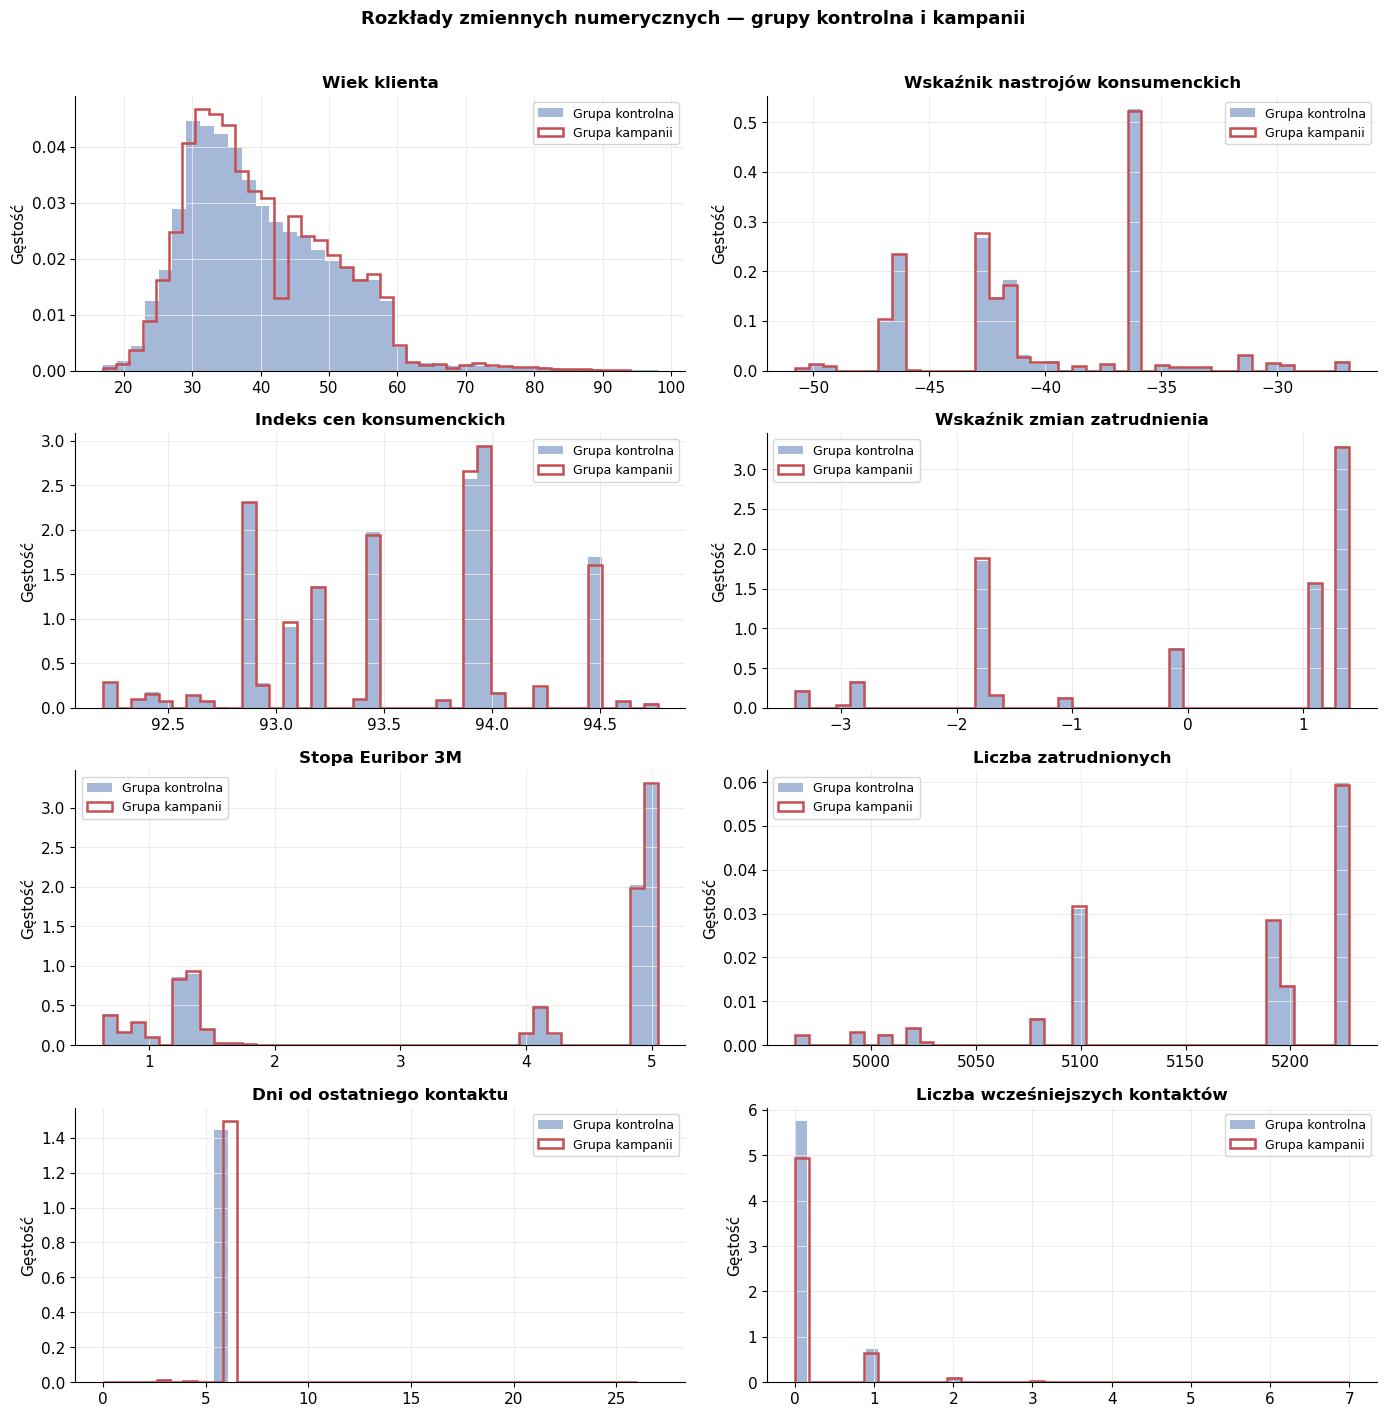

In [70]:
# 3.3 Rozkłady cech numerycznych
control   = df[df["W"] == 0].copy()   # odświeżamy po transformacji pdays
treatment = df[df["W"] == 1].copy()   # odświeżamy po transformacji pdays

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e8e8", "grid.linewidth": 0.6,
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
})

COLOR_CONTROL   = "#4C72B0"
COLOR_TREATMENT = "#C44E52"

NUMERIC_LABELS = {
    "age":            "Wiek klienta",
    "cons.conf.idx":  "Wskaźnik nastrojów konsumenckich",
    "cons.price.idx": "Indeks cen konsumenckich",
    "emp.var.rate":   "Wskaźnik zmian zatrudnienia",
    "euribor3m":      "Stopa Euribor 3M",
    "nr.employed":    "Liczba zatrudnionych",
    "pdays_cleaned":  "Dni od ostatniego kontaktu",
    "previous":       "Liczba wcześniejszych kontaktów",
}

existing = [c for c in NUMERIC_LABELS if c in df.columns]
n = len(existing)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 3.5 * ((n + 1) // 2)))
axes = axes.flatten()

for i, col in enumerate(existing):
    ax = axes[i]
    ax.hist(control[col].dropna(),   bins=40, alpha=0.5, density=True,
            color=COLOR_CONTROL,   label="Grupa kontrolna")
    ax.hist(treatment[col].dropna(), bins=40, alpha=1.0, density=True,
            color=COLOR_TREATMENT, label="Grupa kampanii",
            histtype="step", linewidth=1.8)
    ax.set_title(NUMERIC_LABELS[col])
    ax.set_ylabel("Gęstość")
    ax.legend(fontsize=9)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Rozkłady zmiennych numerycznych — grupy kontrolna i kampanii",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_numeric_distributions.png", bbox_inches="tight", dpi=150)
plt.show()

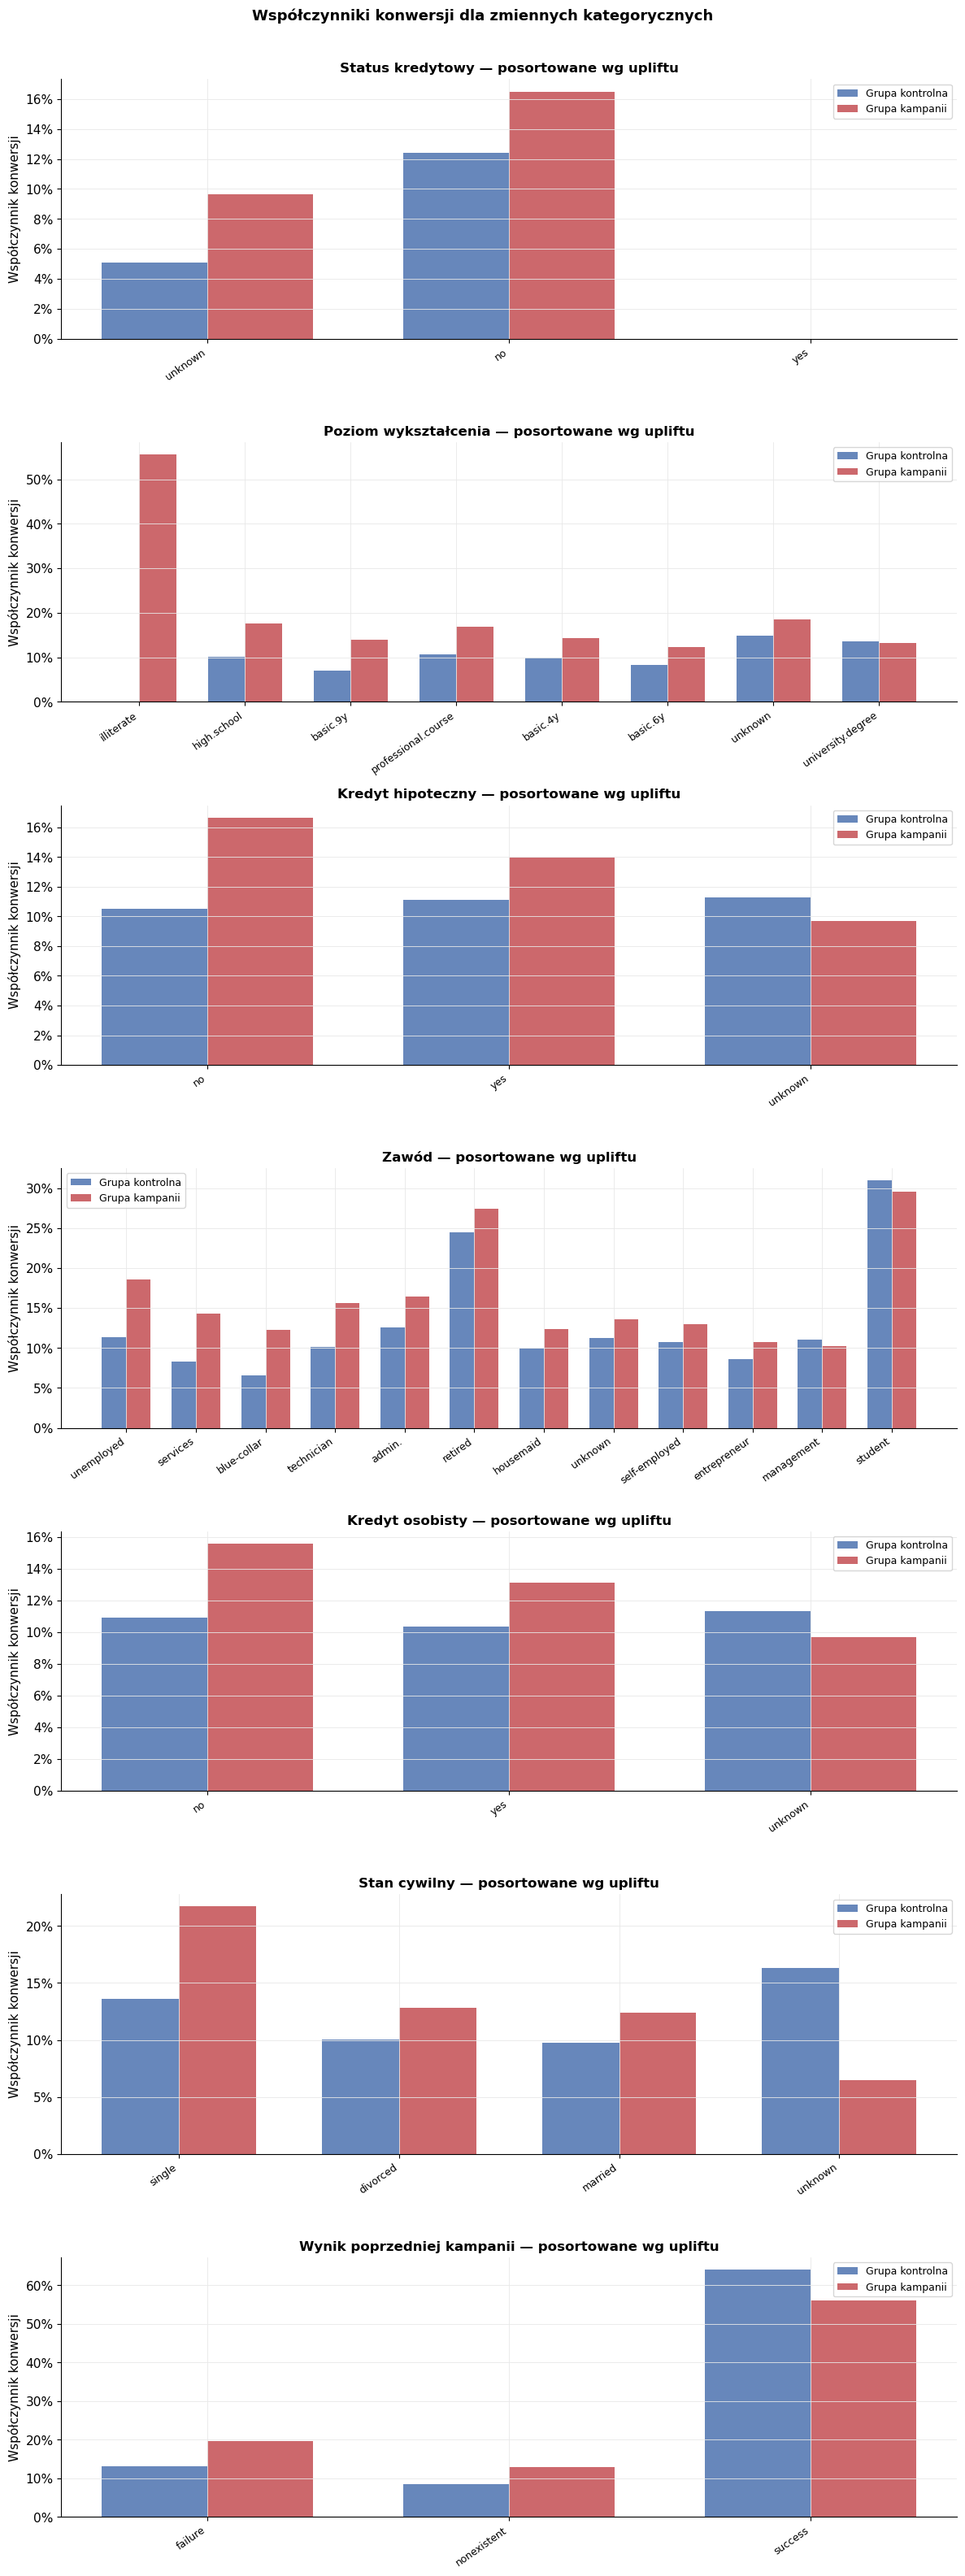

In [46]:
# 3.4 CR per kategoria
import matplotlib.ticker as mticker

CAT_EXCLUDE = {"contact", "month", "day_of_week"}
cat_cols_clean = [c for c in categorical_cols if c not in CAT_EXCLUDE]

CAT_LABELS = {
    "default":  "Status kredytowy",
    "education": "Poziom wykształcenia",
    "housing":  "Kredyt hipoteczny",
    "job":      "Zawód",
    "loan":     "Kredyt osobisty",
    "marital":  "Stan cywilny",
    "poutcome": "Wynik poprzedniej kampanii",
}

n_cat = len(cat_cols_clean)
fig, axes = plt.subplots(n_cat, 1, figsize=(12, 4.5 * n_cat))
if n_cat == 1:
    axes = [axes]

for i, col in enumerate(cat_cols_clean):
    ax = axes[i]
    cr_t = df[df["W"]==1].groupby(col)[TARGET_COL].mean().rename("Grupa kampanii")
    cr_c = df[df["W"]==0].groupby(col)[TARGET_COL].mean().rename("Grupa kontrolna")
    cr_cat = pd.concat([cr_c, cr_t], axis=1).dropna()
    cr_cat["uplift"] = cr_cat["Grupa kampanii"] - cr_cat["Grupa kontrolna"]
    cr_cat = cr_cat.sort_values("uplift", ascending=False)

    x = np.arange(len(cr_cat))
    ax.bar(x - 0.175, cr_cat["Grupa kontrolna"], 0.35,
           color=COLOR_CONTROL,   alpha=0.85, label="Grupa kontrolna")
    ax.bar(x + 0.175, cr_cat["Grupa kampanii"],  0.35,
           color=COLOR_TREATMENT, alpha=0.85, label="Grupa kampanii")
    ax.set_xticks(x)
    ax.set_xticklabels(cr_cat.index, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel("Współczynnik konwersji")
    ax.set_title(f"{CAT_LABELS.get(col, col)} — posortowane wg upliftu")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.legend(fontsize=9)

fig.suptitle("Współczynniki konwersji dla zmiennych kategorycznych",
             fontsize=13, fontweight="bold", y=1.005)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_cr_per_category.png", bbox_inches="tight", dpi=150)
plt.show()

In [47]:
# 3.5 pdays=999
if "pdays" in df.columns:
    # 1. Tworzymy czystą flagę binarną (1 = był kontakt, 0 = nigdy nie kontaktowano)
    df["was_contacted_before"] = (df["pdays"] != 999).astype(int)
    
    # 2. Obliczamy medianę dni kontaktu TYLKO dla osób, które faktycznie go miały
    median_pdays = df.loc[df["pdays"] != 999, "pdays"].median()
    
    # 3. Tworzymy pdays_cleaned: jeśli pdays != 999, zostawiamy wartość; 
    #    jeśli pdays == 999, wstawiamy obliczoną medianę
    df["pdays_cleaned"] = df["pdays"].where(df["pdays"] != 999, median_pdays)
    
    # 4. Bezpiecznie usuwamy oryginalną, "niebezpieczną" kolumnę pdays
    df = df.drop(columns=["pdays"])
    
    print("\n=== Transformacja pdays zakończona ===")
    print(f"  Utworzono flagę 'was_contacted_before'")
    print(f"  Utworzono 'pdays_cleaned' (zastąpiono 999 wartością mediany: {median_pdays:.1f})")
    print(f"  Usunięto oryginalną kolumnę 'pdays'")


=== Transformacja pdays zakończona ===
  Utworzono flagę 'was_contacted_before'
  Utworzono 'pdays_cleaned' (zastąpiono 999 wartością mediany: 6.0)
  Usunięto oryginalną kolumnę 'pdays'


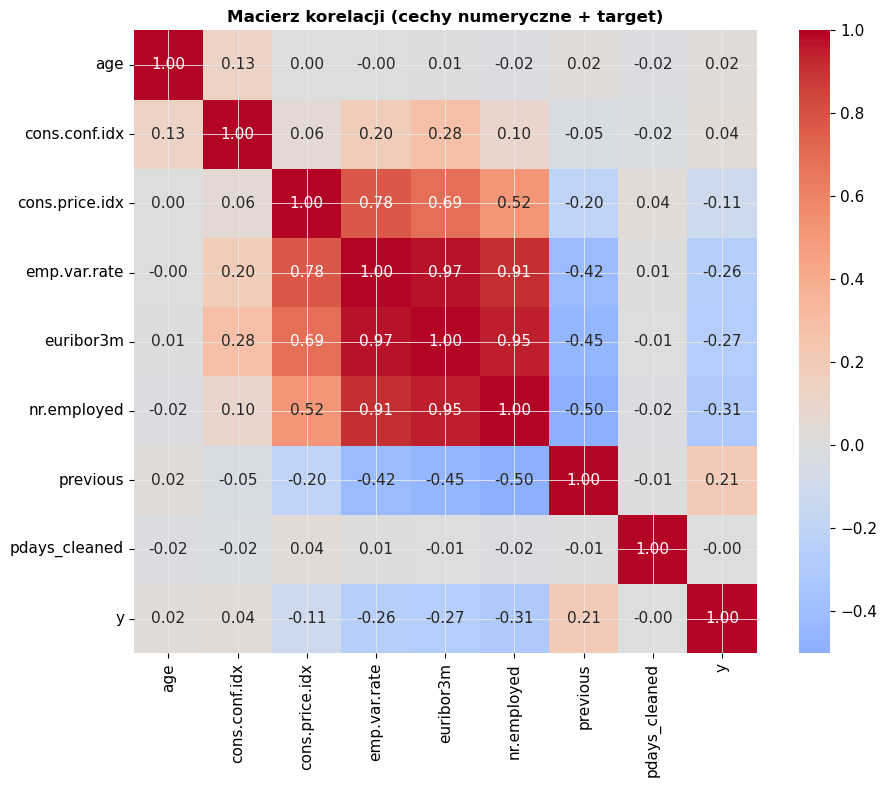

In [48]:
# 3.6 Macierz korelacji
existing_num_cols = [col for col in numeric_cols if col in df.columns]
if "pdays_cleaned" in df.columns and "pdays_cleaned" not in existing_num_cols:
    existing_num_cols.append("pdays_cleaned")

num_for_corr = existing_num_cols + [TARGET_COL]

plt.figure(figsize=(10, 8))
corr = df[num_for_corr].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Macierz korelacji (cechy numeryczne + target)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_correlation_matrix.png", bbox_inches="tight")
plt.show()

In [49]:
### 4. Preprocessing — Pipeline i Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Stan kolumn po dotychczasowych transformacjach:
# Usunięte z modelu:
#   - duration        (leakage — znana dopiero po rozmowie)
#   - test_control_flag (zakodowana jako W)
#   - campaign        (liczba kontaktów, skorelowana z W)
# Dodane: was_contacted_before, pdays_cleaned

COLS_DROP = ["duration", "test_control_flag", "campaign"]  # leakage + meta

df_model = df.drop(columns=[c for c in COLS_DROP if c in df.columns], errors="ignore")

print("Kolumny do modelowania:", df_model.columns.tolist())
print("Shape:", df_model.shape)

# Podział na cechy / target / treatment
X = df_model.drop(columns=["y", "W"])
y = df_model["y"]
W = df_model["W"]

print("\nX shape:", X.shape)
print("y distribution:\n", y.value_counts())
print("W distribution:\n", W.value_counts())

# Identyfikacja typów kolumn
numeric_features     = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("\nNumeric features:    ", numeric_features)
print("Categorical features:", categorical_features)

# Pipeline numeryczny
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # braki → mediana
    ("scaler",  StandardScaler()),                   # standaryzacja dla LR
])

# Pipeline kategoryczny
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Połączony preprocessor
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline,     numeric_features),
    ("cat", categorical_pipeline, categorical_features),
], remainder="drop")   # drop = nic niespodziewanego nie wejdzie

print("\nPreprocessor zdefiniowany ✅")
print(f"  Numeric:     {len(numeric_features)} kolumn")
print(f"  Categorical: {len(categorical_features)} kolumn")

Kolumny do modelowania: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'W', 'was_contacted_before', 'pdays_cleaned']
Shape: (41188, 21)

X shape: (41188, 19)
y distribution:
 y
0    36020
1     5168
Name: count, dtype: int64
W distribution:
 W
0    24712
1    16476
Name: count, dtype: int64

Numeric features:     ['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted_before', 'pdays_cleaned']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Preprocessor zdefiniowany ✅
  Numeric:     9 kolumn
  Categorical: 10 kolumn


In [50]:
### 5. Podział Train / Val / Test i Fit Preprocessora
from sklearn.model_selection import train_test_split
import numpy as np

# Stratyfikacja po y × W (4 kombinacje)
strat_key = y.astype(str) + "_" + W.astype(str)
print("Klucze stratyfikacji:\n", strat_key.value_counts())

# Train 60% / temp 40%
X_train, X_temp, y_train, y_temp, W_train, W_temp = train_test_split(
    X, y, W,
    test_size=0.40,
    stratify=strat_key,
    random_state=RANDOM_SEED
)

# Val 20% / Test 20% z temp
strat_temp = y_temp.astype(str) + "_" + W_temp.astype(str)

X_val, X_test, y_val, y_test, W_val, W_test = train_test_split(
    X_temp, y_temp, W_temp,
    test_size=0.50,
    stratify=strat_temp,
    random_state=RANDOM_SEED
)

print(f"\nTrain: {len(X_train):>6}  ({len(X_train)/len(X)*100:.1f}%)")
print(f"Val:   {len(X_val):>6}  ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test:  {len(X_test):>6}  ({len(X_test)/len(X)*100:.1f}%)")

# Weryfikacja stratyfikacji
for name, ys, ws in [("Train", y_train, W_train),
                      ("Val",   y_val,   W_val),
                      ("Test",  y_test,  W_test)]:
    cr_c = ys[ws==0].mean()
    cr_t = ys[ws==1].mean()
    w_ratio = ws.mean()
    print(f"  {name}: CR_control={cr_c:.4f}  CR_treatment={cr_t:.4f}  "
          f"treatment_ratio={w_ratio:.4f}")

# Fit preprocessora tylko na train
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

# Nazwy kolumn po OHE
ohe_cols = preprocessor.named_transformers_["cat"]["encoder"].get_feature_names_out(categorical_features)
feature_names = numeric_features + ohe_cols.tolist()

print(f"\nShape po preprocessingu:")
print(f"  X_train_proc: {X_train_proc.shape}")
print(f"  X_val_proc:   {X_val_proc.shape}")
print(f"  X_test_proc:  {X_test_proc.shape}")
print(f"  Feature names ({len(feature_names)}): {feature_names[:10]} ...")

Klucze stratyfikacji:
 0_0    22028
0_1    13992
1_0     2684
1_1     2484
Name: count, dtype: int64

Train:  24712  (60.0%)
Val:     8238  (20.0%)
Test:    8238  (20.0%)
  Train: CR_control=0.1086  CR_treatment=0.1507  treatment_ratio=0.4000
  Val: CR_control=0.1087  CR_treatment=0.1508  treatment_ratio=0.4001
  Test: CR_control=0.1086  CR_treatment=0.1508  treatment_ratio=0.4000

Shape po preprocessingu:
  X_train_proc: (24712, 62)
  X_val_proc:   (8238, 62)
  X_test_proc:  (8238, 62)
  Feature names (62): ['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted_before', 'pdays_cleaned', 'job_admin.'] ...


In [51]:
### 6. Modelowanie Uplift — T-Learner (LR, XGB, LGBM)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

# Wagi klas dla niezbalansowanego targetu
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos = neg / pos
print(f"scale_pos_weight: {scale_pos:.2f}  (neg={neg}, pos={pos})")

# Definicje modeli bazowych
base_models = {
    "LR": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        C=0.1
    ),
    "XGB": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        scale_pos_weight=scale_pos,
        random_state=RANDOM_SEED,
        eval_metric="auc",
        verbosity=0
    ),
    "LGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        scale_pos_weight=scale_pos,
        random_state=RANDOM_SEED,
        verbose=-1
    ),
}

scale_pos_weight: 6.97  (neg=21612, pos=3100)


In [52]:
# Liczymy propensity score — prawdopodobieństwo bycia w grupie kampanii
# IPW wagi wyrównują niezbalansowanie 60/40 między grupami
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

propensity_model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
propensity_model.fit(X_train_proc, W_train.values)

ps_train = propensity_model.predict_proba(X_train_proc)[:, 1]
ps_train = np.clip(ps_train, 0.05, 0.95)  # stabilizacja ekstremalnych wag

# Wagi IPW: treatment dostaje 1/ps, control dostaje 1/(1-ps)
ipw_weights = np.where(
    W_train.values == 1,
    1 / ps_train,
    1 / (1 - ps_train)
)
print(f"Propensity score — mean: {ps_train.mean():.3f}  "
      f"min: {ps_train.min():.3f}  max: {ps_train.max():.3f}")
print(f"IPW weights — mean: {ipw_weights.mean():.3f}  "
      f"min: {ipw_weights.min():.3f}  max: {ipw_weights.max():.3f}")

Propensity score — mean: 0.404  min: 0.050  max: 0.950
IPW weights — mean: 1.168  min: 1.053  max: 20.000


In [53]:
# 6.1 T-Learner: osobny model dla treatment i control
# Trenujemy Model_T na danych treatment, Model_C na danych control
# Uplift = P(y=1|x, W=1) - P(y=1|x, W=0)

mask_train_t = (W_train == 1)
mask_train_c = (W_train == 0)

X_train_t = X_train_proc[mask_train_t]
y_train_t = y_train.values[mask_train_t]
X_train_c = X_train_proc[mask_train_c]
y_train_c = y_train.values[mask_train_c]

print(f"\nTrain treatment: {X_train_t.shape[0]} obs  (CR={y_train_t.mean():.4f})")
print(f"Train control:   {X_train_c.shape[0]} obs  (CR={y_train_c.mean():.4f})")

t_learner_models = {}   # {"LR": {"T": model_T, "C": model_C}, ...}
t_learner_uplift = {}   # {"LR": uplift_scores_val, ...}

for name, base_clf in base_models.items():
    print(f"\n── T-Learner [{name}] ────────────────────────────")

    # Klonujemy żeby każdy model był niezależny
    from sklearn.base import clone
    model_T = clone(base_clf)
    model_C = clone(base_clf)

    # Trenowanie
    model_T.fit(X_train_t, y_train_t,
            sample_weight=ipw_weights[mask_train_t])
    model_C.fit(X_train_c, y_train_c,
            sample_weight=ipw_weights[mask_train_c])

    # Predykcja uplift na val
    p_t = model_T.predict_proba(X_val_proc)[:, 1]
    p_c = model_C.predict_proba(X_val_proc)[:, 1]
    uplift_val = p_t - p_c

    t_learner_models[name] = {"T": model_T, "C": model_C}
    t_learner_uplift[name] = uplift_val

    # Podstawowe statystyki uplift
    print(f"  Uplift val — mean: {uplift_val.mean():+.4f}  "
          f"std: {uplift_val.std():.4f}  "
          f"min: {uplift_val.min():+.4f}  "
          f"max: {uplift_val.max():+.4f}")

    # Cross-val AUC na train (Model_T i Model_C osobno)
    auc_t = cross_val_score(clone(base_clf), X_train_t, y_train_t,
                            cv=5, scoring="roc_auc").mean()
    auc_c = cross_val_score(clone(base_clf), X_train_c, y_train_c,
                            cv=5, scoring="roc_auc").mean()
    print(f"  CV AUC Model_T: {auc_t:.4f}  |  Model_C: {auc_c:.4f}")

print("\nT-Learner gotowy ✅")


Train treatment: 9885 obs  (CR=0.1507)
Train control:   14827 obs  (CR=0.1086)

── T-Learner [LR] ────────────────────────────
  Uplift val — mean: -0.0229  std: 0.1447  min: -0.5658  max: +0.4734
  CV AUC Model_T: 0.7182  |  Model_C: 0.7602

── T-Learner [XGB] ────────────────────────────
  Uplift val — mean: +0.0601  std: 0.2258  min: -0.8804  max: +0.7755
  CV AUC Model_T: 0.6904  |  Model_C: 0.7813

── T-Learner [LGBM] ────────────────────────────


C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Uplift val — mean: +0.0647  std: 0.2207  min: -0.8196  max: +0.7940


C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-package

  CV AUC Model_T: 0.7001  |  Model_C: 0.7825

T-Learner gotowy ✅


C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [54]:
# 6.2 S-Learner (XGB) i Class Variable Transformation (CVT)
import numpy as np
from xgboost import XGBClassifier
from sklearn.base import clone

# Dołączamy W do macierzy cech
X_train_s = np.column_stack([X_train_proc, W_train.values])
X_val_s   = np.column_stack([X_val_proc,   W_val.values])
X_test_s  = np.column_stack([X_test_proc,  W_test.values])

s_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos,
    random_state=RANDOM_SEED,
    eval_metric="auc",
    verbosity=0
)
s_model.fit(X_train_s, y_train.values)

# Counterfactual: każdy klient z W=1 i W=0
X_val_w1 = X_val_s.copy(); X_val_w1[:, -1] = 1
X_val_w0 = X_val_s.copy(); X_val_w0[:, -1] = 0

p_t_s = s_model.predict_proba(X_val_w1)[:, 1]
p_c_s = s_model.predict_proba(X_val_w0)[:, 1]
uplift_s = p_t_s - p_c_s

s_learner_uplift = {"XGB": uplift_s}

print("── S-Learner [XGB] ────────────────────────────")
print(f"  Uplift val — mean: {uplift_s.mean():+.4f}  "
      f"std: {uplift_s.std():.4f}  "
      f"min: {uplift_s.min():+.4f}  "
      f"max: {uplift_s.max():+.4f}")

── S-Learner [XGB] ────────────────────────────
  Uplift val — mean: +0.0840  std: 0.0811  min: -0.3088  max: +0.3617


In [55]:
### 6.3 Class Variable Transformation (CVT)
from lightgbm import LGBMClassifier

# Tworzymy Z na train
Z_train = ((W_train.values == 1) & (y_train.values == 1)) | \
          ((W_train.values == 0) & (y_train.values == 0))
Z_train = Z_train.astype(int)

print(f"\n── CVT ────────────────────────────────────────")
print(f"  Z distribution: Z=1: {Z_train.sum()}  Z=0: {(Z_train==0).sum()}")

cvt_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=RANDOM_SEED,
    verbose=-1
)
cvt_model.fit(X_train_proc, Z_train)

# Uplift = 2*P(Z=1|x) - 1
p_z_val = cvt_model.predict_proba(X_val_proc)[:, 1]
uplift_cvt = 2 * p_z_val - 1

cvt_uplift = {"LGBM": uplift_cvt}

print(f"  Uplift val — mean: {uplift_cvt.mean():+.4f}  "
      f"std: {uplift_cvt.std():.4f}  "
      f"min: {uplift_cvt.min():+.4f}  "
      f"max: {uplift_cvt.max():+.4f}")

print("\nS-Learner i CVT gotowe ✅")


── CVT ────────────────────────────────────────
  Z distribution: Z=1: 14707  Z=0: 10005
  Uplift val — mean: +0.1910  std: 0.7555  min: -0.9738  max: +0.9756

S-Learner i CVT gotowe ✅


C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [56]:
### 6.4 Causal Forest DML
from econml.dml import CausalForestDML
from sklearn.ensemble import GradientBoostingRegressor

cf_model = CausalForestDML(
    model_y=GradientBoostingRegressor(
        n_estimators=100, max_depth=4, random_state=RANDOM_SEED
    ),
    model_t=GradientBoostingRegressor(
        n_estimators=100, max_depth=4, random_state=RANDOM_SEED
    ),
    n_estimators=1000,
    min_samples_leaf=50,   # było 20 → zwiększamy dla stabilności
    max_depth=5,           # było None → ograniczamy głębokość
    random_state=RANDOM_SEED,
    verbose=0,
    cv=5
)

print("Trenuję Causal Forest DML...")
cf_model.fit(
    Y=y_train.values,
    T=W_train.values,
    X=X_train_proc
)

uplift_cf_val = cf_model.effect(X_val_proc).flatten()

# Kilka obserwacji może mieć ekstremalny uplift — przycinam do [-1, 1]
n_clipped = ((uplift_cf_val < -1) | (uplift_cf_val > 1)).sum()
uplift_cf_val_clipped = uplift_cf_val.clip(-1, 1)

causal_forest_uplift = {"CF": uplift_cf_val_clipped}

if 'all_uplift_val' not in locals() and 'all_uplift_val' not in globals():
    all_uplift_val = {}

all_uplift_val["CF"] = uplift_cf_val_clipped

print("── Causal Forest DML ──────────────────────────")
print(f"  Uplift (raw)    — mean: {uplift_cf_val.mean():+.4f}  std: {uplift_cf_val.std():.4f}  "
      f"min: {uplift_cf_val.min():+.4f}  max: {uplift_cf_val.max():+.4f}")
print(f"  Clipped obs (|uplift|>1): {n_clipped} ({n_clipped/len(uplift_cf_val)*100:.1f}%)")
print(f"  Uplift (clipped) — mean: {uplift_cf_val_clipped.mean():+.4f}  "
      f"std: {uplift_cf_val_clipped.std():.4f}")

# Przedziały ufności per klient
cate_ci = cf_model.effect_interval(X_val_proc, alpha=0.05)
ci_lower = cate_ci[0].flatten().clip(-1, 1)
ci_upper = cate_ci[1].flatten().clip(-1, 1)
print(f"  95% CI szerokość — mean: {(ci_upper - ci_lower).mean():.4f}")
print(f"  % obs z CI nie obejmującym 0: "
      f"{((ci_lower > 0) | (ci_upper < 0)).mean()*100:.1f}%")

print("\nCausal Forest gotowy ✅")

Trenuję Causal Forest DML...
── Causal Forest DML ──────────────────────────
  Uplift (raw)    — mean: +0.0463  std: 0.0373  min: -0.1561  max: +0.1368
  Clipped obs (|uplift|>1): 0 (0.0%)
  Uplift (clipped) — mean: +0.0463  std: 0.0373
  95% CI szerokość — mean: 0.1755
  % obs z CI nie obejmującym 0: 17.7%

Causal Forest gotowy ✅


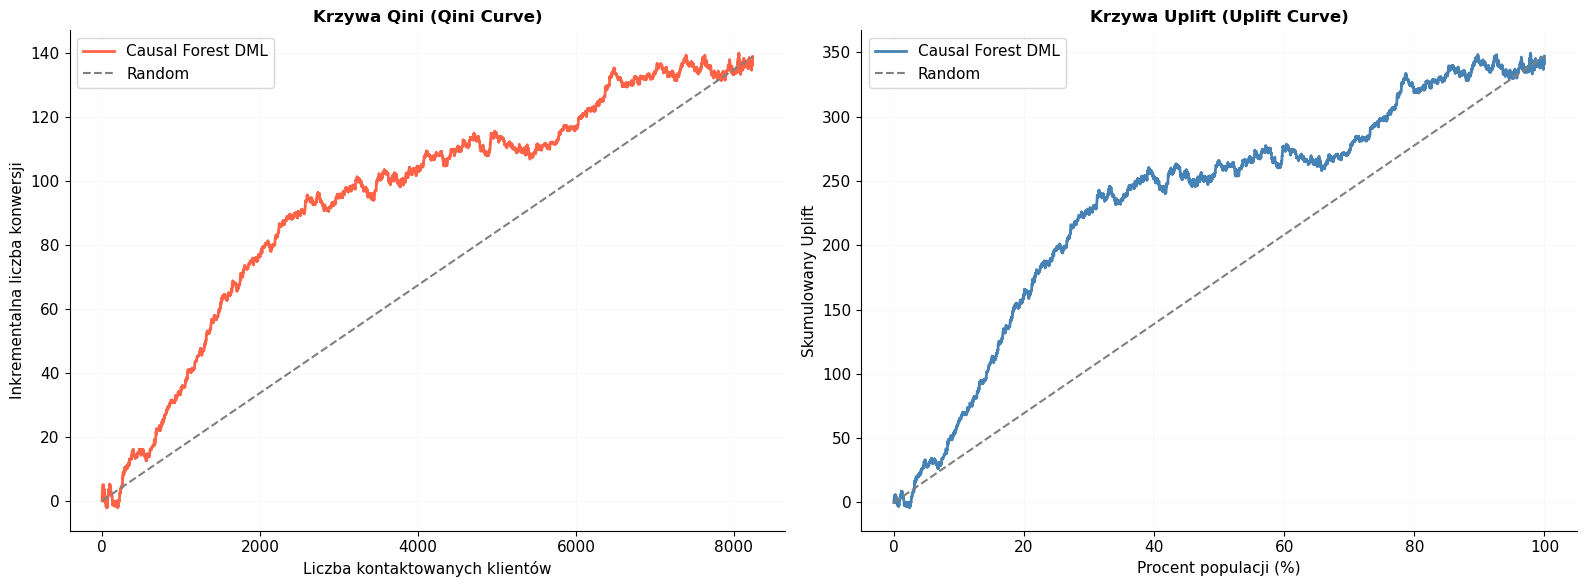


=== METRYKI UPLIFT DLA CAUSAL FOREST ===
  Współczynnik Qini: 0.0625
  AUUC Score:        0.0251


In [57]:
### 7. Wizualizacja — Krzywe Qini i Uplift (Causal Forest)
import matplotlib.pyplot as plt
import numpy as np
from sklift.metrics import qini_auc_score, uplift_auc_score

def get_qini_curve_data(y_true, uplift, treatment):
    y_true, uplift, treatment = np.array(y_true), np.array(uplift), np.array(treatment)
    desc_score_indices = np.argsort(uplift, kind="mergesort")[::-1]
    y_true, treatment = y_true[desc_score_indices], treatment[desc_score_indices]
    
    y_tr_cumsum = np.cumsum(y_true * treatment)
    y_ctrl_cumsum = np.cumsum(y_true * (1 - treatment))
    tr_cumsum = np.cumsum(treatment)
    ctrl_cumsum = np.cumsum(1 - treatment)
    
    with np.errstate(invalid='ignore', divide='ignore'):
        scaled_ctrl_clicks = y_ctrl_cumsum * (tr_cumsum / np.where(ctrl_cumsum == 0, 1, ctrl_cumsum))
        scaled_ctrl_clicks[ctrl_cumsum == 0] = 0
        
    qini_values = y_tr_cumsum - scaled_ctrl_clicks
    qini_values = np.insert(qini_values, 0, 0)
    x_values = np.linspace(0, len(y_true), len(qini_values))
    random_line = np.linspace(0, qini_values[-1], len(qini_values))
    return x_values, qini_values, random_line

def get_uplift_curve_data(y_true, uplift, treatment):
    y_true, uplift, treatment = np.array(y_true), np.array(uplift), np.array(treatment)
    desc_score_indices = np.argsort(uplift, kind="mergesort")[::-1]
    y_true, treatment = y_true[desc_score_indices], treatment[desc_score_indices]
    
    y_tr_cumsum = np.cumsum(y_true * treatment)
    y_ctrl_cumsum = np.cumsum(y_true * (1 - treatment))
    tr_cumsum = np.cumsum(treatment)
    ctrl_cumsum = np.cumsum(1 - treatment)
    
    with np.errstate(invalid='ignore', divide='ignore'):
        cr_tr = y_tr_cumsum / np.where(tr_cumsum == 0, 1, tr_cumsum)
        cr_ctrl = y_ctrl_cumsum / np.where(ctrl_cumsum == 0, 1, ctrl_cumsum)
        cr_tr[tr_cumsum == 0] = 0
        cr_ctrl[ctrl_cumsum == 0] = 0
        
    uplift_values = (cr_tr - cr_ctrl) * (tr_cumsum + ctrl_cumsum)
    uplift_values = np.insert(uplift_values, 0, 0)
    x_values = np.linspace(0, 100, len(uplift_values))
    random_line = np.linspace(0, uplift_values[-1], len(uplift_values))
    return x_values, uplift_values, random_line

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

x_qini, y_qini, rand_qini = get_qini_curve_data(y_val, uplift_cf_val_clipped, W_val)
ax1.plot(x_qini, y_qini, label="Causal Forest DML", color="tomato", lw=2)
ax1.plot(x_qini, rand_qini, label="Random", color="grey", linestyle="--")
ax1.set_title("Krzywa Qini (Qini Curve)")
ax1.set_xlabel("Liczba kontaktowanych klientów")
ax1.set_ylabel("Inkrementalna liczba konwersji")
ax1.legend()
ax1.grid(True, alpha=0.3)

x_up, y_up, rand_up = get_uplift_curve_data(y_val, uplift_cf_val_clipped, W_val)
ax2.plot(x_up, y_up, label="Causal Forest DML", color="steelblue", lw=2)
ax2.plot(x_up, rand_up, label="Random", color="grey", linestyle="--")
ax2.set_title("Krzywa Uplift (Uplift Curve)")
ax2.set_xlabel("Procent populacji (%)")
ax2.set_ylabel("Skumulowany Uplift")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "uplift_models_evaluation.png", bbox_inches="tight")
plt.show()

qini_coefficient = qini_auc_score(y_true=y_val, uplift=uplift_cf_val_clipped, treatment=W_val)
auuc_score = uplift_auc_score(y_true=y_val, uplift=uplift_cf_val_clipped, treatment=W_val)

print("\n=== METRYKI UPLIFT DLA CAUSAL FOREST ===")
print(f"  Współczynnik Qini: {qini_coefficient:.4f}")
print(f"  AUUC Score:        {auuc_score:.4f}")
print("========================================")

In [58]:
### 8. Porównanie Modeli
# 8.1 AUUC na Val Secie
all_uplift_val = {}

for name, uplift in t_learner_uplift.items():
    all_uplift_val[f"T-Learner [{name}]"] = uplift

for name, uplift in s_learner_uplift.items():
    all_uplift_val[f"S-Learner [{name}]"] = uplift

all_uplift_val["CF"] = np.clip(cf_model.effect(X_val_proc), -1, 1)
all_uplift_val["CVT"] = uplift_cvt
all_uplift_val_ranked = {k: v for k, v in all_uplift_val.items() if k != "CVT"}

import matplotlib.pyplot as plt
import numpy as np
from sklift.metrics import qini_auc_score, qini_curve

auuc_results = {}

for model_name, uplift_vals in all_uplift_val_ranked.items():
    auuc = qini_auc_score(y_val, uplift_vals, W_val)
    auuc_results[model_name] = {
        "AUUC": auuc,
        "Uplift mean": uplift_vals.mean()
    }

if "CF" not in auuc_results:
    cf_uplift_val_clipped = np.clip(cf_model.effect(X_val), -1, 1)
    auuc_cf = qini_auc_score(y_val, cf_uplift_val_clipped, W_val)
    auuc_results["CF"] = {
        "AUUC": auuc_cf,
        "Uplift mean": cf_uplift_val_clipped.mean()
    }

# Tabela porównawcza
print("=== UPLIFT METRICS — znormalizowana Qini (val set) ===\n")
print(f"{'Model':<20} {'AUUC':>8}  {'Uplift mean':>12}")
print("-" * 45)
for name, metrics in sorted(auuc_results.items(), key=lambda x: -x[1]["AUUC"]):
    print(f"{name:<20} {metrics['AUUC']:>8.5f}  {metrics['Uplift mean']:>+12.4f}")

best_model_name = max(auuc_results, key=lambda x: auuc_results[x]["AUUC"])
print(f"\n✅ Najlepszy model (val set): {best_model_name}  "
      f"AUUC={auuc_results[best_model_name]['AUUC']:.5f}")

=== UPLIFT METRICS — znormalizowana Qini (val set) ===

Model                    AUUC   Uplift mean
---------------------------------------------
T-Learner [LR]        0.16966       -0.0229
T-Learner [XGB]       0.16506       +0.0601
T-Learner [LGBM]      0.15761       +0.0647
S-Learner [XGB]       0.11255       +0.0840
CF                    0.06254       +0.0463

✅ Najlepszy model (val set): T-Learner [LR]  AUUC=0.16966


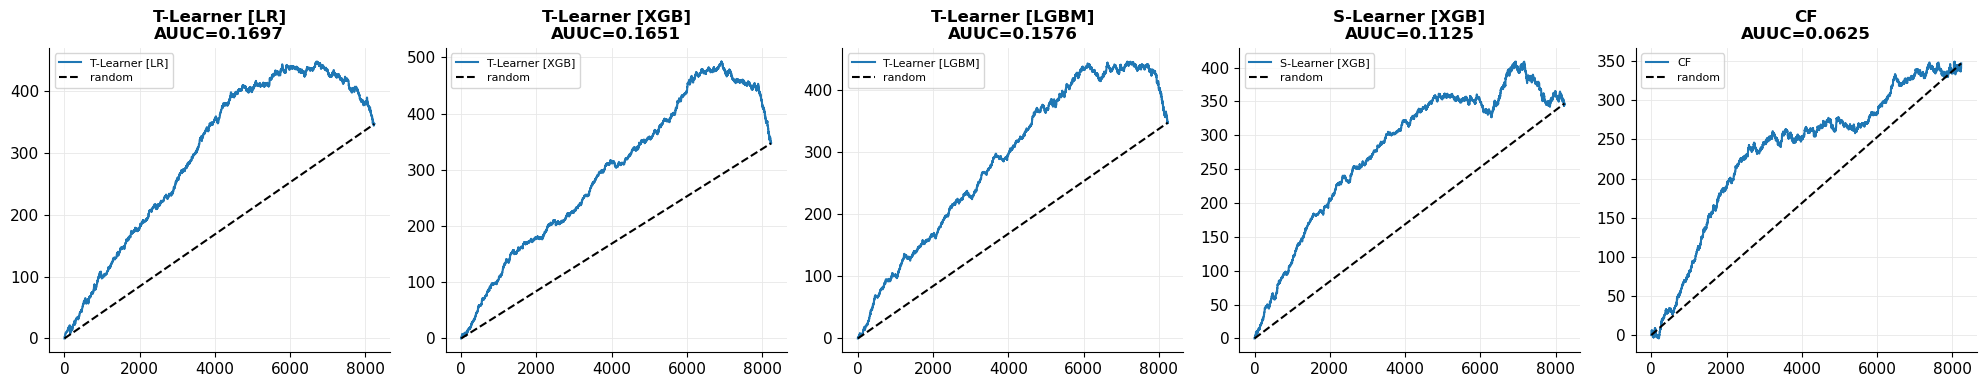

In [59]:
# 8.2 Sanity Check — Kierunek Rankingu
from sklift.metrics import uplift_curve

fig, axes = plt.subplots(1, len(auuc_results), figsize=(4 * len(auuc_results), 4))
for ax, (name, metrics) in zip(axes, sorted(auuc_results.items(), 
                                             key=lambda x: -x[1]["AUUC"])):
    uplift_vals = all_uplift_val_ranked.get(name, all_uplift_val.get(name))
    cx, cy = uplift_curve(y_val, uplift_vals, W_val)
    ax.plot(cx, cy, label=name)
    ax.plot([0, cx[-1]], [0, cy[-1]], 'k--', label='random')
    ax.set_title(f"{name}\nAUUC={metrics['AUUC']:.4f}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sanity_check_uplift_curves.png", bbox_inches="tight")
plt.show()

In [60]:
### 9. Ewaluacja Finalna
# 9.1 Ewaluacja Finalna na Test Secie — Wszystkie Modele
import numpy as np
from sklift.metrics import qini_auc_score, qini_curve

auuc_test_results = {}

for model_name in all_uplift_val_ranked.keys():
    if model_name == "S-Learner [XGB]":
        X_test_w1 = np.column_stack([X_test_proc, np.ones(len(X_test_proc))])
        X_test_w0 = np.column_stack([X_test_proc, np.zeros(len(X_test_proc))])
        uplift_test = (s_model.predict_proba(X_test_w1)[:, 1]
                       - s_model.predict_proba(X_test_w0)[:, 1])
    elif model_name in ("T-Learner [XGB]", "T-Learner [LGBM]", "T-Learner [LR]"):
        key = model_name.split("[")[1].rstrip("]")  # "XGB", "LGBM", "LR"
        uplift_test = (t_learner_models[key]["T"].predict_proba(X_test_proc)[:, 1]
                       - t_learner_models[key]["C"].predict_proba(X_test_proc)[:, 1])
    else:
        continue

    auuc_test = qini_auc_score(y_test, uplift_test, W_test)
    auuc_test_results[model_name] = {
        "AUUC_test": auuc_test,
        "uplift_array": uplift_test
    }

# Causal Forest osobno
cf_uplift_test = np.clip(cf_model.effect(X_test_proc), -1, 1)
auuc_test_results["CF"] = {
    "AUUC_test": qini_auc_score(y_test, cf_uplift_test, W_test),
    "uplift_array": cf_uplift_test
}

print("=== FINALNY WYNIK NA TEST — wszystkie modele ===\n")
print(f"{'Model':<20} {'AUUC test':>10}")
print("-" * 35)
for name, res in sorted(auuc_test_results.items(), key=lambda x: -x[1]["AUUC_test"]):
    print(f"{name:<20} {res['AUUC_test']:>10.5f}")

best_model_name = max(auuc_test_results, key=lambda x: auuc_test_results[x]["AUUC_test"])
best_uplift_test = auuc_test_results[best_model_name]["uplift_array"]
best_auuc_test = auuc_test_results[best_model_name]["AUUC_test"]

print(f"\n✅ Wybrany model (test set): {best_model_name}  AUUC={best_auuc_test:.5f}")
print(f"   Raw lift test: +{(treatment[TARGET_COL].mean() - control[TARGET_COL].mean()):.4f}")

C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


=== FINALNY WYNIK NA TEST — wszystkie modele ===

Model                 AUUC test
-----------------------------------
T-Learner [LR]          0.20833
T-Learner [LGBM]        0.17896
T-Learner [XGB]         0.17758
S-Learner [XGB]         0.14392
CF                      0.09262

✅ Wybrany model (test set): T-Learner [LR]  AUUC=0.20833
   Raw lift test: +0.0422


C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


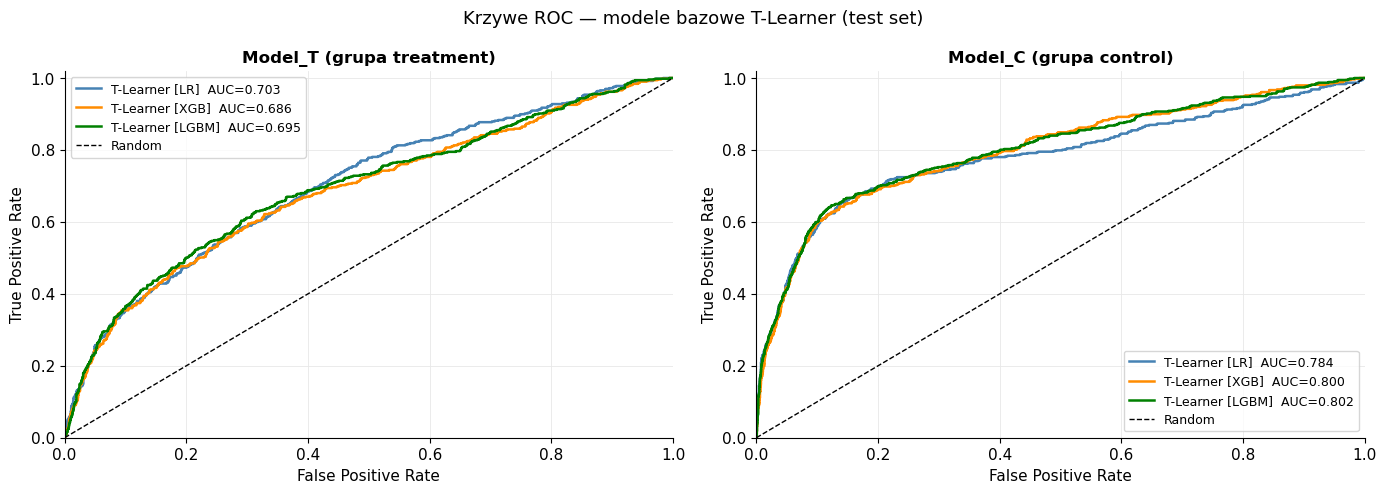

In [61]:
### 9.1b Krzywe ROC — modele bazowe T i C (wymaganie zadania)
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"LR": "steelblue", "XGB": "darkorange", "LGBM": "green"}

for side, ax, title, mask in [
    ("T", axes[0], "Model_T (grupa treatment)", W_test == 1),
    ("C", axes[1], "Model_C (grupa control)",   W_test == 0),
]:
    X_side = X_test_proc[mask]
    y_side = y_test.values[mask]

    for name in ["LR", "XGB", "LGBM"]:
        model = t_learner_models[name][side]
        y_prob = model.predict_proba(X_side)[:, 1]
        fpr, tpr, _ = roc_curve(y_side, y_prob)
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=colors[name], lw=1.8,
                label=f"T-Learner [{name}]  AUC={roc_auc:.3f}")

    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])

fig.suptitle("Krzywe ROC — modele bazowe T-Learner (test set)", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", bbox_inches="tight")
plt.show()


=== BOOTSTRAP CI — 1000 resampli (test set) ===
  AUUC test:    0.20833
  95% CI:       [0.16791, 0.24538]
  CI > 0:       ✅ model istotny statystycznie


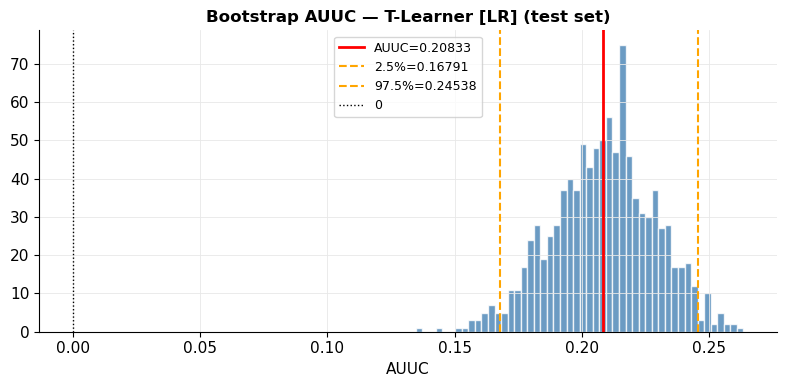

In [62]:
# 9.2 Bootstrap CI — Istotność Statystyczna
from sklift.metrics import qini_auc_score
import matplotlib.pyplot as plt
import numpy as np

print(f"\n=== BOOTSTRAP CI — 1000 resampli (test set) ===")
np.random.seed(RANDOM_SEED)
N_test = len(best_uplift_test)
bootstrap_auucs = []

for _ in range(1000):
    idx = np.random.choice(N_test, size=N_test, replace=True)
    auuc_b = qini_auc_score(
        y_true=y_test.values[idx],
        uplift=best_uplift_test[idx],
        treatment=W_test.values[idx]
    )
    bootstrap_auucs.append(auuc_b)

bootstrap_auucs = np.array(bootstrap_auucs)
ci_low  = np.percentile(bootstrap_auucs, 2.5)
ci_high = np.percentile(bootstrap_auucs, 97.5)

print(f"  AUUC test:    {best_auuc_test:.5f}")
print(f"  95% CI:       [{ci_low:.5f}, {ci_high:.5f}]")
print(f"  CI > 0:       {'✅ model istotny statystycznie' if ci_low > 0 else '⚠ brak istotności'}")

plt.figure(figsize=(8, 4))
plt.hist(bootstrap_auucs, bins=50, color="steelblue", edgecolor="white", alpha=0.8)
plt.axvline(best_auuc_test, color="red",    lw=2,    label=f"AUUC={best_auuc_test:.5f}")
plt.axvline(ci_low,         color="orange", lw=1.5, ls="--", label=f"2.5%={ci_low:.5f}")
plt.axvline(ci_high,        color="orange", lw=1.5, ls="--", label=f"97.5%={ci_high:.5f}")
plt.axvline(0,              color="black",  lw=1,   ls=":",  label="0")
plt.xlabel("AUUC")
plt.title(f"Bootstrap AUUC — {best_model_name} (test set)")
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "bootstrap_auuc.png", bbox_inches="tight")
plt.show()

=== TABELA DECYLOWA (test set, decyl 1 = najwyższy uplift score) ===

 decile   n  n_t  n_c   CR_t   CR_c  uplift  inc_conv
      1 824  561  263 0.1640 0.0418  0.1222      68.5
      2 824  413  411 0.1574 0.0487  0.1087      44.9
      3 824  330  494 0.1606 0.0547  0.1060      35.0
      4 823  365  458 0.1315 0.0830  0.0485      17.7
      5 824  306  518 0.2157 0.0811  0.1346      41.2
      6 824  250  574 0.1720 0.1254  0.0466      11.6
      7 823  291  532 0.1375 0.1203  0.0172       5.0
      8 824  290  534 0.1345 0.1273  0.0071       2.1
      9 824  257  567 0.1206 0.1287 -0.0081      -2.1
     10 824  232  592 0.0862 0.2061 -0.1199     -27.8

Łączne incremental conversions (cała populacja): 196.1

=== INCREMENTAL GAIN — targeting top X% ===

  Top 10%: n=  824  CR_t=0.1640  CR_c=0.0418  uplift=+0.1222  inc_conv=68.5
  Top 20%: n= 1648  CR_t=0.1612  CR_c=0.0460  uplift=+0.1152  inc_conv=112.2
  Top 30%: n= 2472  CR_t=0.1610  CR_c=0.0497  uplift=+0.1114  inc_conv=145.2
  To

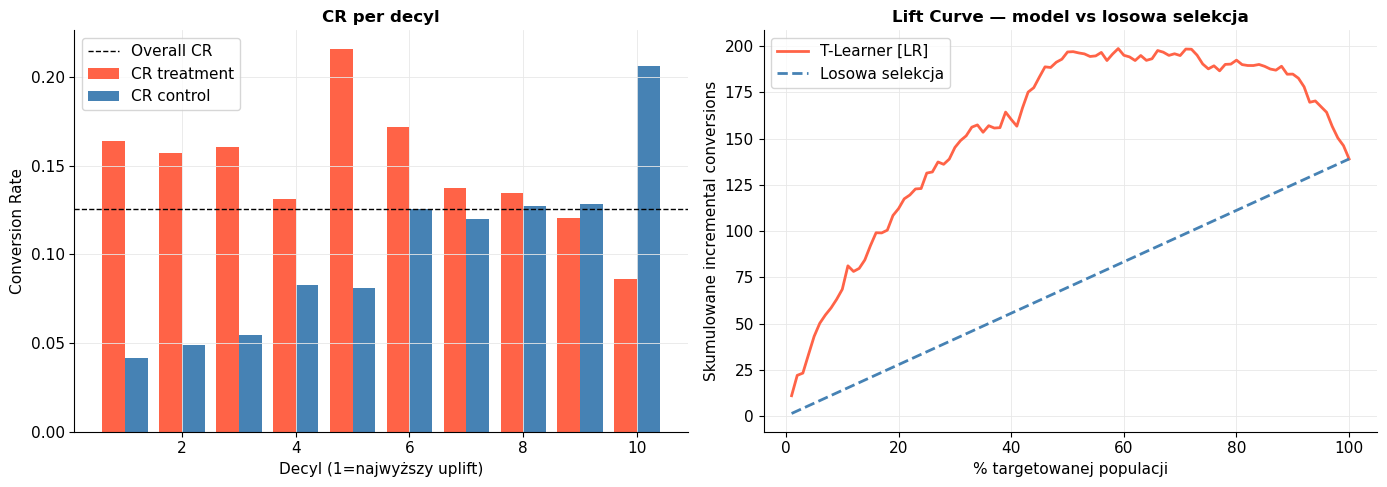

In [63]:
### 10. Analiza Biznesowa — Incremental Gain per Decyl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Budujemy tabelę na test secie — sortujemy klientów malejąco po uplift score
df_test = pd.DataFrame({
    "uplift_score": best_uplift_test,
    "y":            y_test.values,
    "w":            W_test.values
}).sort_values("uplift_score", ascending=False).reset_index(drop=True)

N_test  = len(df_test)
N_t_all = (df_test["w"] == 1).sum()
N_c_all = (df_test["w"] == 0).sum()

# Decyl 1 = klienci z najwyższym uplift score
df_test["decile"] = pd.qcut(df_test.index, 10, labels=range(1, 11))

decile_stats = []
for dec in range(1, 11):
    subset   = df_test[df_test["decile"] == dec]
    n        = len(subset)
    n_t      = (subset["w"] == 1).sum()
    n_c      = (subset["w"] == 0).sum()
    cr_t     = subset[subset["w"]==1]["y"].mean() if n_t > 0 else 0
    cr_c     = subset[subset["w"]==0]["y"].mean() if n_c > 0 else 0
    uplift   = cr_t - cr_c
    inc_conv = uplift * n_t if n_t > 0 else 0
    decile_stats.append({
        "decile": dec, "n": n, "n_t": n_t, "n_c": n_c,
        "CR_t": round(cr_t, 4), "CR_c": round(cr_c, 4),
        "uplift": round(uplift, 4), "inc_conv": round(inc_conv, 1),
    })

decile_df = pd.DataFrame(decile_stats)
print("=== TABELA DECYLOWA (test set, decyl 1 = najwyższy uplift score) ===\n")
print(decile_df.to_string(index=False))

total_inc = decile_df["inc_conv"].sum()
print(f"\nŁączne incremental conversions (cała populacja): {total_inc:.1f}")

# Ile zyskujemy kontaktując tylko top X% populacji
print("\n=== INCREMENTAL GAIN — targeting top X% ===\n")
for pct in [10, 20, 30, 50]:
    top_n  = int(np.ceil(pct / 100 * N_test))
    subset = df_test.head(top_n)
    n_t    = (subset["w"] == 1).sum()
    n_c    = (subset["w"] == 0).sum()
    cr_t   = subset[subset["w"]==1]["y"].mean() if n_t > 0 else 0
    cr_c   = subset[subset["w"]==0]["y"].mean() if n_c > 0 else 0
    uplift = cr_t - cr_c
    inc    = uplift * n_t
    print(f"  Top {pct:>2}%: n={top_n:>5}  CR_t={cr_t:.4f}  CR_c={cr_c:.4f}  "
          f"uplift={uplift:+.4f}  inc_conv={inc:.1f}")

# Sleeping Dogs — klienci których kampania zniechęca, lepiej ich nie targetować
THRESHOLD = -0.02
sleeping  = df_test[df_test["uplift_score"] < THRESHOLD]
print(f"\n=== SLEEPING DOGS (uplift_score < {THRESHOLD}) ===")
print(f"  Liczba: {len(sleeping)} ({len(sleeping)/N_test*100:.1f}% populacji)")
if len(sleeping) > 0:
    cr_t_sl = sleeping[sleeping["w"]==1]["y"].mean()
    cr_c_sl = sleeping[sleeping["w"]==0]["y"].mean()
    print(f"  CR_t={cr_t_sl:.4f}  CR_c={cr_c_sl:.4f}  uplift={cr_t_sl-cr_c_sl:+.4f}")
    print(f"  → Nie targetować tych klientów — kampania im szkodzi lub nie pomaga")

# Wykresy: CR per decyl i lift curve model vs losowa selekcja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = decile_df["decile"]
axes[0].bar(x - 0.2, decile_df["CR_t"], 0.4, label="CR treatment", color="tomato")
axes[0].bar(x + 0.2, decile_df["CR_c"], 0.4, label="CR control",   color="steelblue")
axes[0].axhline(df_test["y"].mean(), color="black", ls="--", lw=1, label="Overall CR")
axes[0].set_xlabel("Decyl (1=najwyższy uplift)")
axes[0].set_ylabel("Conversion Rate")
axes[0].set_title("CR per decyl")
axes[0].legend()

cum_inc_model  = []
cum_inc_random = []
raw_lift = y_test.values[W_test.values==1].mean() - y_test.values[W_test.values==0].mean()

for pct in range(1, 101):
    top_n  = int(np.ceil(pct / 100 * N_test))
    subset = df_test.head(top_n)
    n_t    = (subset["w"] == 1).sum()
    cr_t   = subset[subset["w"]==1]["y"].mean() if n_t > 0 else 0
    cr_c   = subset[subset["w"]==0]["y"].mean() if n_t > 0 else 0
    cum_inc_model.append((cr_t - cr_c) * n_t)
    cum_inc_random.append(raw_lift * (pct / 100) * N_t_all)

axes[1].plot(range(1, 101), cum_inc_model,  color="tomato",    lw=2, label=f"{best_model_name}")
axes[1].plot(range(1, 101), cum_inc_random, color="steelblue", lw=2, ls="--", label="Losowa selekcja")
axes[1].set_xlabel("% targetowanej populacji")
axes[1].set_ylabel("Skumulowane incremental conversions")
axes[1].set_title("Lift Curve — model vs losowa selekcja")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "business_analysis.png", bbox_inches="tight")
plt.show()

In [64]:
# 10.1 Sleeping Dogs — analiza w strefie targetowania
from sklift.metrics import qini_curve

# Liczymy optimum lokalnie na podstawie najlepszego modelu
cx_test, cy_test  = qini_curve(y_test, best_uplift_test, W_test)
y_random_line     = np.linspace(0, cy_test[-1], len(cx_test))
distances         = cy_test - y_random_line
optimal_idx       = np.argmax(distances)
optimal_customers = int(cx_test[optimal_idx])
target_pct        = optimal_customers / cx_test[-1]

print(f"Zakładany zasięg kampanii: top {target_pct*100:.1f}% bazy ({optimal_customers} klientów)\n")
print(f"{'Model':<20} {'AUUC':>8}  {'SD ogółem':>10}  {f'SD w top {target_pct*100:.0f}%':>13}  komentarz")
print("-" * 85)

for name, res in auuc_test_results.items():
    uplift_arr       = res["uplift_array"]
    n_targeted       = int(len(uplift_arr) * target_pct)
    sd_overall       = (uplift_arr < -0.02).mean() * 100
    auuc             = res["AUUC_test"]

    uplift_sorted    = np.sort(uplift_arr)[::-1]
    n_sd_in_target   = (uplift_sorted[:n_targeted] < -0.02).sum()
    pct_sd_in_target = n_sd_in_target / n_targeted * 100

    if pct_sd_in_target > 20:
        comment = "⚠️  dużo SD w kampanii"
    elif pct_sd_in_target > 10:
        comment = "⚠️  umiarkowanie"
    else:
        comment = "✅  SD poza strefą"

    print(f"{name:<20} {auuc:>8.4f}  {sd_overall:>8.1f}%  "
          f"{n_sd_in_target:>5} ({pct_sd_in_target:>4.1f}%)  {comment}")

best_model_by_auuc = max(auuc_test_results, key=lambda x: auuc_test_results[x]["AUUC_test"])
best_auuc_val      = auuc_test_results[best_model_by_auuc]["AUUC_test"]
best_uplift_sorted = np.sort(auuc_test_results[best_model_by_auuc]["uplift_array"])[::-1]
n_targeted_best    = int(len(best_uplift_sorted) * target_pct)
n_sd_best          = (best_uplift_sorted[:n_targeted_best] < -0.02).sum()

print(f"\n✅ Rekomendowany model: {best_model_by_auuc}")
print(f"   AUUC={best_auuc_val:.4f} — najwyższy spośród wszystkich modeli.")
print(f"   Sleeping dogs w strefie targetowania: {n_sd_best} klientów ({n_sd_best/n_targeted_best*100:.1f}%)")
print(f"   Model rankuje je nisko — przy cutoffie top {target_pct*100:.0f}% większość odpada.")
print(f"   W produkcji: dodatkowo odetnij uplift < 0 przed scoringiem.")

Zakładany zasięg kampanii: top 51.2% bazy (4214 klientów)

Model                    AUUC   SD ogółem   SD w top 51%  komentarz
-------------------------------------------------------------------------------------
T-Learner [LR]         0.2083      50.8%    160 ( 3.8%)  ✅  SD poza strefą
T-Learner [XGB]        0.1776      32.4%      0 ( 0.0%)  ✅  SD poza strefą
T-Learner [LGBM]       0.1790      32.2%      0 ( 0.0%)  ✅  SD poza strefą
S-Learner [XGB]        0.1439       6.6%      0 ( 0.0%)  ✅  SD poza strefą
CF                     0.0926       3.2%      0 ( 0.0%)  ✅  SD poza strefą

✅ Rekomendowany model: T-Learner [LR]
   AUUC=0.2083 — najwyższy spośród wszystkich modeli.
   Sleeping dogs w strefie targetowania: 160 klientów (3.8%)
   Model rankuje je nisko — przy cutoffie top 51% większość odpada.
   W produkcji: dodatkowo odetnij uplift < 0 przed scoringiem.


Liczę SHAP values dla Model_T (treatment)...


C:\Users\User\anaconda3\Lib\site-packages\shap\explainers\_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Liczę SHAP values dla Model_C (control)...
Shape shap_T: (1000, 62)  ✅


C:\Users\User\AppData\Local\Temp\ipykernel_19744\4137305104.py:31: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_T, X_sample, feature_names=feature_names,


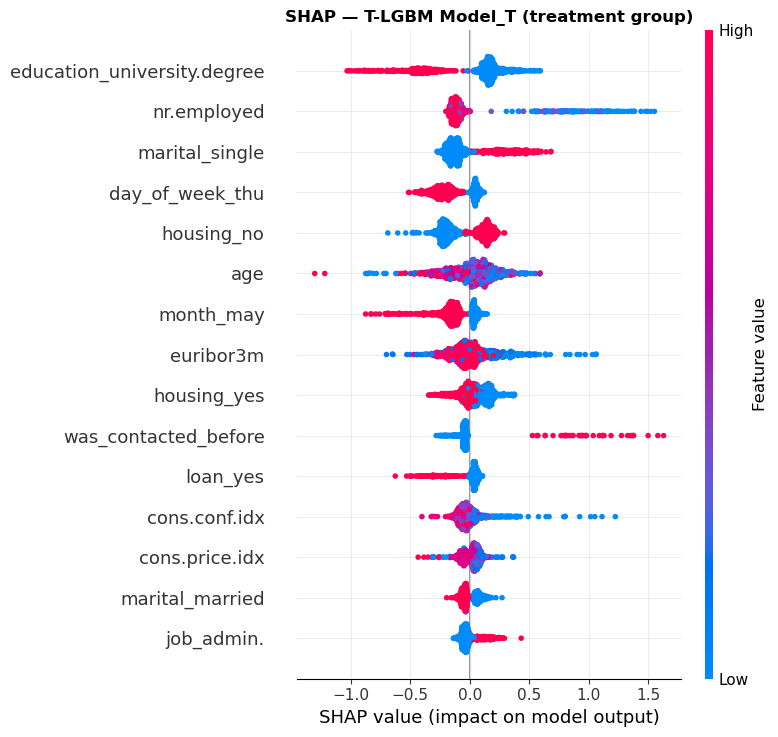

C:\Users\User\AppData\Local\Temp\ipykernel_19744\4137305104.py:39: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_C, X_sample, feature_names=feature_names,


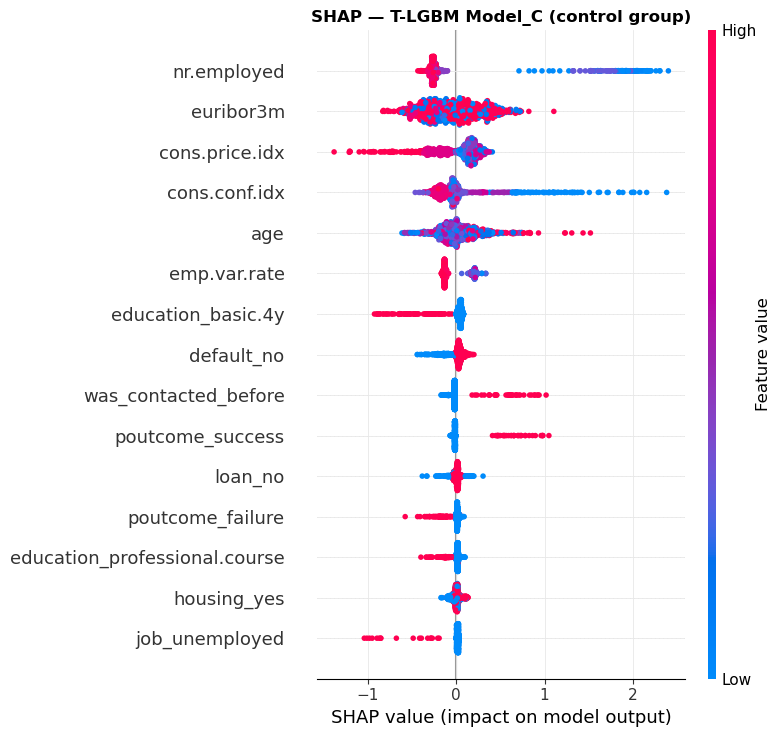


=== TOP 15 cech — różnica SHAP Model_T vs Model_C ===
                    feature  mean_shap_T  mean_shap_C  mean_abs_diff
                  euribor3m     0.134200     0.259275       0.292245
education_university.degree     0.267015     0.019742       0.277018
                        age     0.152165     0.168866       0.253389
                nr.employed     0.216476     0.462174       0.247434
             marital_single     0.182378     0.010978       0.186784
             cons.price.idx     0.062623     0.217780       0.172302
                 housing_no     0.171014     0.027100       0.153343
              cons.conf.idx     0.074717     0.194570       0.144949
               emp.var.rate     0.052040     0.159442       0.108793
                housing_yes     0.097255     0.030348       0.103554
                 job_admin.     0.060228     0.018406       0.072148
            marital_married     0.060255     0.023780       0.066577
         education_basic.4y     0.029579     0.0

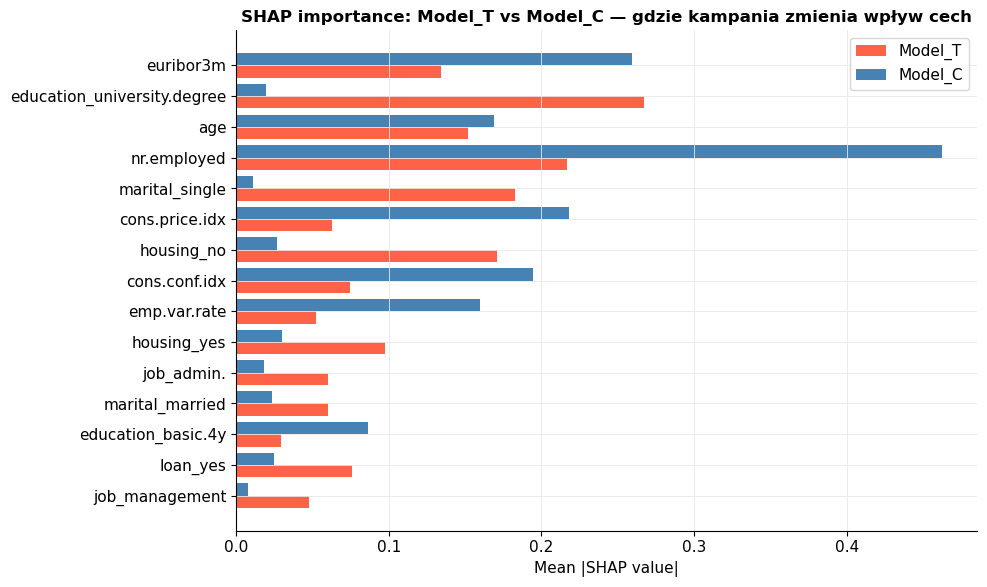

In [71]:
### 11. Analiza SHAP
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_T_lgbm = t_learner_models["LGBM"]["T"]
model_C_lgbm = t_learner_models["LGBM"]["C"]

np.random.seed(RANDOM_SEED)
sample_idx   = np.random.choice(len(X_test_proc), size=1000, replace=False)
X_sample     = X_test_proc[sample_idx]

explainer_T = shap.TreeExplainer(model_T_lgbm)
explainer_C = shap.TreeExplainer(model_C_lgbm)

print("Liczę SHAP values dla Model_T (treatment)...")
shap_T = explainer_T.shap_values(X_sample)
print("Liczę SHAP values dla Model_C (control)...")
shap_C = explainer_C.shap_values(X_sample)

# LGBM zwraca listę [shap_class0, shap_class1] — bierzemy klasę 1
if isinstance(shap_T, list):
    shap_T = shap_T[1]
    shap_C = shap_C[1]

print(f"Shape shap_T: {shap_T.shape}  ✅")

# Beeswarm pokazuje które cechy i w jakim kierunku wpływają na pred
plt.figure()
shap.summary_plot(shap_T, X_sample, feature_names=feature_names,
                  max_display=15, show=False)
plt.title("SHAP — T-LGBM Model_T (treatment group)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_T.png", bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(shap_C, X_sample, feature_names=feature_names,
                  max_display=15, show=False)
plt.title("SHAP — T-LGBM Model_C (control group)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_C.png", bbox_inches="tight")
plt.show()

# Różnica SHAP(T) - SHAP(C) pokazuje które cechy kampania zmienia najbardziej
shap_diff      = shap_T - shap_C
mean_abs_diff  = np.abs(shap_diff).mean(axis=0)

SHAP_EXCLUDE = [col for col in feature_names if 
                any(col.startswith(p) for p in 
                    ["month_", "day_of_week_", "contact_"])]

diff_df = pd.DataFrame({
    "feature":       feature_names,
    "mean_shap_T":   np.abs(shap_T).mean(axis=0),
    "mean_shap_C":   np.abs(shap_C).mean(axis=0),
    "mean_abs_diff": mean_abs_diff
})
diff_df = diff_df[~diff_df["feature"].isin(SHAP_EXCLUDE)]
diff_df = diff_df.sort_values("mean_abs_diff", ascending=False).head(15)

print("\n=== TOP 15 cech — różnica SHAP Model_T vs Model_C ===")
print(diff_df.to_string(index=False))

# Wykres porównawczy
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(diff_df))
ax.barh(y_pos - 0.2, diff_df["mean_shap_T"][::-1],   0.4, label="Model_T", color="tomato")
ax.barh(y_pos + 0.2, diff_df["mean_shap_C"][::-1],   0.4, label="Model_C", color="steelblue")
ax.set_yticks(y_pos)
ax.set_yticklabels(diff_df["feature"][::-1])
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("SHAP importance: Model_T vs Model_C — gdzie kampania zmienia wpływ cech")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_diff.png", bbox_inches="tight")
plt.show()

In [66]:
# 9.3 Placebo Test — Weryfikacja Modeli
np.random.seed(RANDOM_SEED)
N_placebo = 100
placebo_auucs = {}

for model_name, res in auuc_test_results.items():
    placebo_scores = []
    for _ in range(N_placebo):
        W_perm = W_test.sample(frac=1).values
        try:
            s = qini_auc_score(y_test, res["uplift_array"], W_perm)
            placebo_scores.append(s)
        except Exception:
            pass
    placebo_auucs[model_name] = np.mean(placebo_scores)

placebo_passed = all(
    auuc_test_results[m]["AUUC_test"] > placebo_auucs[m]
    for m in auuc_test_results
)
placebo_status = "✅ wszystkie modele zaliczone" if placebo_passed else "⚠️ niektóre modele nie przeszły"

print("=== PLACEBO TEST ===")
print(f"{'Model':<20} {'AUUC real':>10} {'AUUC placebo':>13} {'OK?':>5}")
print("-" * 55)
for m in auuc_test_results:
    real = auuc_test_results[m]["AUUC_test"]
    plac = placebo_auucs[m]
    ok = "✅" if real > plac else "⚠️"
    print(f"{m:<20} {real:>10.5f} {plac:>13.5f} {ok:>5}")

=== PLACEBO TEST ===
Model                 AUUC real  AUUC placebo   OK?
-------------------------------------------------------
T-Learner [LR]          0.20833       0.00142     ✅
T-Learner [XGB]         0.17758      -0.00164     ✅
T-Learner [LGBM]        0.17896       0.00039     ✅
S-Learner [XGB]         0.14392       0.00228     ✅
CF                      0.09262      -0.00285     ✅


In [67]:
### 12. Podsumowanie Analizy
from sklift.metrics import qini_auc_score
import numpy as np

raw_lift = treatment[TARGET_COL].mean() - control[TARGET_COL].mean()

# Bootstrap CI
np.random.seed(RANDOM_SEED)
N_test = len(best_uplift_test)
boot_auuc = []
for _ in range(1000):
    idx = np.random.choice(N_test, N_test, replace=True)
    try:
        b = qini_auc_score(y_test.iloc[idx], best_uplift_test[idx], W_test.iloc[idx])
        boot_auuc.append(b)
    except Exception:
        pass
ci_low, ci_high = np.percentile(boot_auuc, [2.5, 97.5])

# Top 10% uplift
df_test_summary = pd.DataFrame({
    "uplift": best_uplift_test,
    "y":      y_test.values,
    "W":      W_test.values
})
df_test_summary["decile"] = pd.qcut(df_test_summary["uplift"], 10,
                                     labels=False, duplicates="drop")
top10        = df_test_summary[df_test_summary["decile"] == 9]
uplift_top10 = top10[top10["W"]==1]["y"].mean() - top10[top10["W"]==0]["y"].mean()
sleeping_dogs_pct = (best_uplift_test < -0.02).mean() * 100

# Profil klienta z SHAP diff
shap_diff_mean = pd.DataFrame({
    "feature":       feature_names,
    "mean_shap_diff": shap_diff.mean(axis=0)
}).sort_values("mean_shap_diff", ascending=False)

top_positive = shap_diff_mean[shap_diff_mean["mean_shap_diff"] > 0].head(5)
top_negative = shap_diff_mean[shap_diff_mean["mean_shap_diff"] < 0].tail(5)
ci_status    = '✅ cały przedział > 0' if ci_low > 0 else '⚠️ CI obejmuje 0'

top_pos_str = "".join(f"     • {row.feature}  (SHAP diff: +{row.mean_shap_diff:.4f})\n" for _, row in top_positive.iterrows())
top_neg_str = "".join(f"     • {row.feature}  (SHAP diff: {row.mean_shap_diff:.4f})\n" for _, row in top_negative.iterrows())

print(f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║                         PODSUMOWANIE ANALIZY                                 ║
╚══════════════════════════════════════════════════════════════════════════════╝

── 1. MODEL ──────────────────────────────────────────────────────────────────
  Wybrany model:  {best_model_name}
  AUUC (test):    {best_auuc_test:.5f}
  95% CI:         [{ci_low:.3f}, {ci_high:.3f}]  {ci_status}
  Placebo test:   {placebo_status}

── 2. EFEKT KAMPANII ─────────────────────────────────────────────────────────
  Raw lift:       +{raw_lift:.2%}  (CR_treatment={treatment[TARGET_COL].mean():.2%} vs CR_control={control[TARGET_COL].mean():.2%})
  Top 10% uplift: +{uplift_top10:.2%} — kampania {uplift_top10/raw_lift:.1f}x skuteczniejsza niż średnia
  Sleeping Dogs:  {sleeping_dogs_pct:.1f}% populacji z uplift < -2%
                  (w strefie targetowania top {target_pct*100:.0f}%: tylko {n_sd_best/n_targeted_best*100:.1f}%)

── 3. PROFIL KLIENTA RESPONSYWNEGO (na podstawie SHAP) ──────────────────────
  ✅ Cechy zwiększające responsywność na kampanię:
{top_pos_str}
  ❌ Cechy zmniejszające responsywność na kampanię:
{top_neg_str}
""")


╔══════════════════════════════════════════════════════════════════════════════╗
║                         PODSUMOWANIE ANALIZY                                 ║
╚══════════════════════════════════════════════════════════════════════════════╝

── 1. MODEL ──────────────────────────────────────────────────────────────────
  Wybrany model:  T-Learner [LR]
  AUUC (test):    0.20833
  95% CI:         [0.168, 0.245]  ✅ cały przedział > 0
  Placebo test:   ✅ wszystkie modele zaliczone

── 2. EFEKT KAMPANII ─────────────────────────────────────────────────────────
  Raw lift:       +4.22%  (CR_treatment=15.08% vs CR_control=10.86%)
  Top 10% uplift: +12.22% — kampania 2.9x skuteczniejsza niż średnia
  Sleeping Dogs:  50.8% populacji z uplift < -2%
                  (w strefie targetowania top 51%: tylko 3.8%)

── 3. PROFIL KLIENTA RESPONSYWNEGO (na podstawie SHAP) ──────────────────────
  ✅ Cechy zwiększające responsywność na kampanię:
     • euribor3m  (SHAP diff: +0.0553)
     • housing_ye

In [68]:
### 13. Optymalny Punkt Odcięcia — Ile Klientów Targetować?
import numpy as np
from sklift.metrics import qini_curve

cx_test, cy_test = qini_curve(y_test, best_uplift_test, W_test)

y_random_line = np.linspace(0, cy_test[-1], len(cx_test))

distances   = cy_test - y_random_line
optimal_idx = np.argmax(distances)

optimal_customers  = int(cx_test[optimal_idx])
optimal_conversions = cy_test[optimal_idx]
optimal_percentage  = (optimal_customers / cx_test[-1]) * 100

print("=== MATEMATYCZNE OPTIMUM MODELU (TEST SET) ===")
print(f"Optymalny punkt odcięcia bazy:    {optimal_customers} klientów")
print(f"Procent rekomendowanej populacji: {optimal_percentage:.1f}% całej bazy")
print(f"Oczekiwana liczba dod. konwersji: {optimal_conversions:.1f}")
print(f"Maksymalna przewaga nad losem:    +{distances[optimal_idx]:.1f} konwersji")
print("==============================================")

=== MATEMATYCZNE OPTIMUM MODELU (TEST SET) ===
Optymalny punkt odcięcia bazy:    4214 klientów
Procent rekomendowanej populacji: 51.2% całej bazy
Oczekiwana liczba dod. konwersji: 199.1
Maksymalna przewaga nad losem:    +127.9 konwersji
